# 05 — Evaluation & Metrics
Evaluate model performance with mAP, precision, recall, and per-class analysis.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from torch.utils.data import DataLoader

from src.model import build_model
from src.evaluate import evaluate_detections, run_evaluation
from src.dataset import MultiModalDataset
from src.utils import load_config, get_device, collate_fn, create_sample_data

%matplotlib inline
device = get_device('auto')

C:\Users\shiva\AppData\Local\Programs\Python\Python39\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Setup
DATA_DIR = os.path.join('..', 'data', 'sample')
if not os.path.exists(os.path.join(DATA_DIR, 'annotations.json')):
    create_sample_data(DATA_DIR, num_samples=30)

cfg = load_config(os.path.join('..', 'configs', 'default.yaml'))
cfg['model']['num_classes'] = 5
cfg['dataset']['img_size'] = [320, 320]

CLASS_NAMES = ['person', 'car', 'bicycle', 'dog', 'other']

# Build model (random weights for demo)
model = build_model(cfg).to(device)

# Try to load trained weights
weights_path = os.path.join('..', 'weights', 'notebook_trained.pth')
if os.path.exists(weights_path):
    ckpt = torch.load(weights_path, map_location=device)
    model.load_state_dict(ckpt['model_state_dict'])
    print('Loaded trained weights')
else:
    print('Using random weights (train first for real metrics)')

model.eval()

# Dataset
dataset = MultiModalDataset(
    root_dir=DATA_DIR,
    annotation_file=os.path.join(DATA_DIR, 'annotations.json'),
    img_size=(320, 320)
)
loader = DataLoader(dataset, batch_size=4, collate_fn=collate_fn)

Loaded trained weights


C:\Users\shiva\AppData\Local\Temp\ipykernel_5832\3616762436.py:18: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(weights_path, map_location=device)


In [3]:
# Run evaluation
metrics = run_evaluation(
    model, loader, device,
    num_classes=5,
    class_names=CLASS_NAMES,
    score_thresh=0.1,
    nms_thresh=0.5
)

print('\n=== Evaluation Results ===')
for key, val in metrics.items():
    if isinstance(val, float):
        print(f'{key}: {val:.4f}')
    elif isinstance(val, dict):
        print(f'\n{key}:')
        for cls_name, cls_metrics in val.items():
            if isinstance(cls_metrics, dict):
                print(f'  {cls_name}: AP={cls_metrics["ap"]:.4f}, '
                      f'P={cls_metrics["precision"]:.4f}, '
                      f'R={cls_metrics["recall"]:.4f}, '
                      f'F1={cls_metrics["f1"]:.4f}')

Evaluating:   0%|          | 0/3 [00:00<?, ?it/s]

Evaluating:  33%|███▎      | 1/3 [00:08<00:17,  8.76s/it]

Evaluating:  67%|██████▋   | 2/3 [00:17<00:08,  8.47s/it]

Evaluating: 100%|██████████| 3/3 [00:21<00:00,  6.52s/it]

Evaluating: 100%|██████████| 3/3 [00:21<00:00,  7.08s/it]


=== Evaluation Results ===
mAP@0.5: 0.0000

per_class@0.5:
  person: AP=0.0000, P=0.0000, R=0.0000, F1=0.0000
  car: AP=0.0000, P=0.0000, R=0.0000, F1=0.0000
  bicycle: AP=0.0000, P=0.0000, R=0.0000, F1=0.0000
  dog: AP=0.0000, P=0.0000, R=0.0000, F1=0.0000
  other: AP=0.0000, P=0.0000, R=0.0000, F1=0.0000
mAP@0.75: 0.0000

per_class@0.75:
  person: AP=0.0000, P=0.0000, R=0.0000, F1=0.0000
  car: AP=0.0000, P=0.0000, R=0.0000, F1=0.0000
  bicycle: AP=0.0000, P=0.0000, R=0.0000, F1=0.0000
  dog: AP=0.0000, P=0.0000, R=0.0000, F1=0.0000
  other: AP=0.0000, P=0.0000, R=0.0000, F1=0.0000


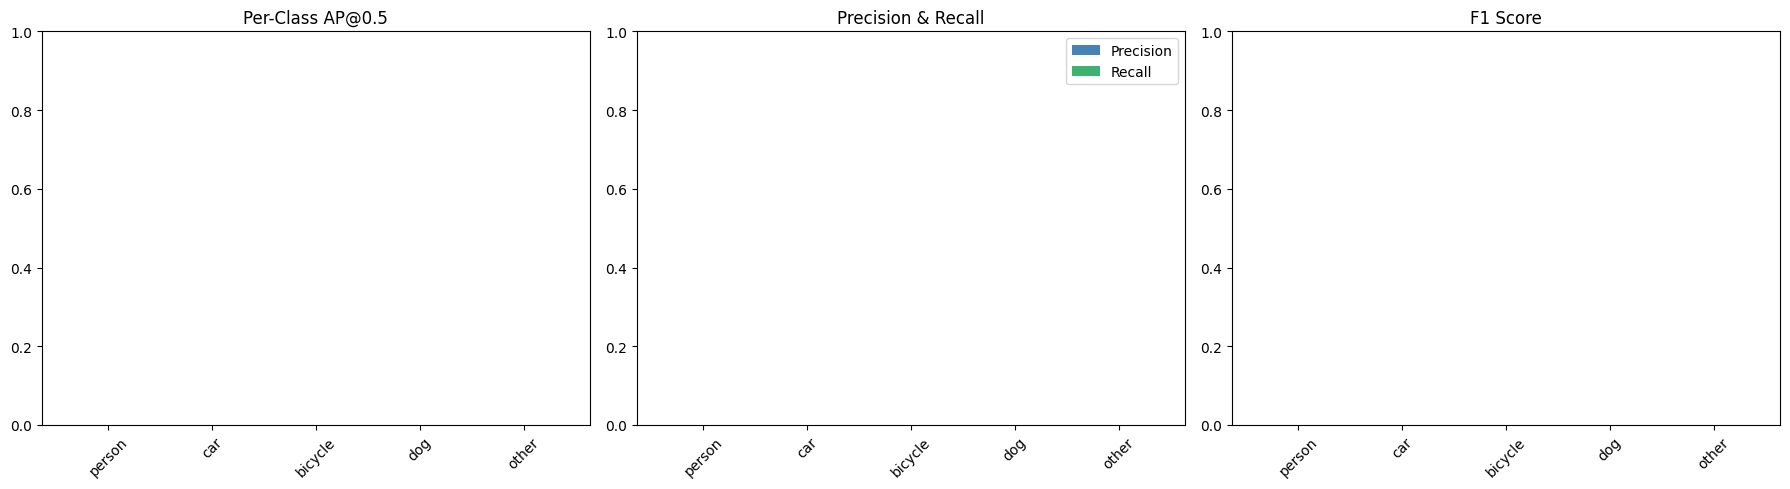

In [4]:
# Visualize per-class metrics
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Get per-class data from metrics
per_class = metrics.get('per_class@0.5', {})
if per_class:
    cls_names = list(per_class.keys())
    aps = [per_class[c].get('ap', 0) for c in cls_names]
    precs = [per_class[c].get('precision', 0) for c in cls_names]
    recs = [per_class[c].get('recall', 0) for c in cls_names]
    
    x = np.arange(len(cls_names))
    
    axes[0].bar(x, aps, color='coral')
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(cls_names, rotation=45)
    axes[0].set_title('Per-Class AP@0.5')
    axes[0].set_ylim(0, 1)
    
    axes[1].bar(x - 0.2, precs, 0.4, label='Precision', color='steelblue')
    axes[1].bar(x + 0.2, recs, 0.4, label='Recall', color='mediumseagreen')
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(cls_names, rotation=45)
    axes[1].set_title('Precision & Recall')
    axes[1].legend()
    axes[1].set_ylim(0, 1)
    
    f1s = [per_class[c].get('f1', 0) for c in cls_names]
    axes[2].bar(x, f1s, color='mediumpurple')
    axes[2].set_xticks(x)
    axes[2].set_xticklabels(cls_names, rotation=45)
    axes[2].set_title('F1 Score')
    axes[2].set_ylim(0, 1)

plt.tight_layout()
plt.show()

In [5]:
# Summary table
if per_class:
    df = pd.DataFrame(per_class).T
    df = df.round(4)
    print('\nMetrics Summary Table:')
    print(df.to_string())
    print(f'\nmAP@0.5: {metrics.get("mAP@0.5", 0):.4f}')


Metrics Summary Table:
          ap  precision  recall   f1  num_gt  num_pred
person   0.0        0.0     0.0  0.0     7.0    1000.0
car      0.0        0.0     0.0  0.0     7.0       0.0
bicycle  0.0        0.0     0.0  0.0     6.0       0.0
dog      0.0        0.0     0.0  0.0     4.0       0.0
other    0.0        0.0     0.0  0.0     6.0       0.0

mAP@0.5: 0.0000
